# CENTAUR news: Mozambique drought

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a timeseries for a subset of the dataset for one of the CENTAUR use case countries. 

## Setup and Settings

#### Load libraries

In [24]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [2]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.NaN  
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [3]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 1940
yyyy_end  = 2025
indicator = "SPEI"
window    = 12
yyyy      = 2025
mm        = "01"
dataset   = "era5"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
#ipath_era5t= f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
country   = "Mozambique"

In [4]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]#[window:]
#pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
#if (yyyy_start - 1940 -window) < 0: 
print(dates)
print(dates.size)
#print(pdate_seq)
#print(pdate_seq.size)

DatetimeIndex(['1940-01-31', '1940-02-29', '1940-03-31', '1940-04-30',
               '1940-05-31', '1940-06-30', '1940-07-31', '1940-08-31',
               '1940-09-30', '1940-10-31',
               ...
               '2024-03-31', '2024-04-30', '2024-05-31', '2024-06-30',
               '2024-07-31', '2024-08-31', '2024-09-30', '2024-10-31',
               '2024-11-30', '2024-12-31'],
              dtype='datetime64[ns]', length=1020, freq='ME')
1020


### Landmask and area

In [5]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

/usr/local/apps/python3/3.11.10-01/lib/python3.11/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.38.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Country / Region of interest

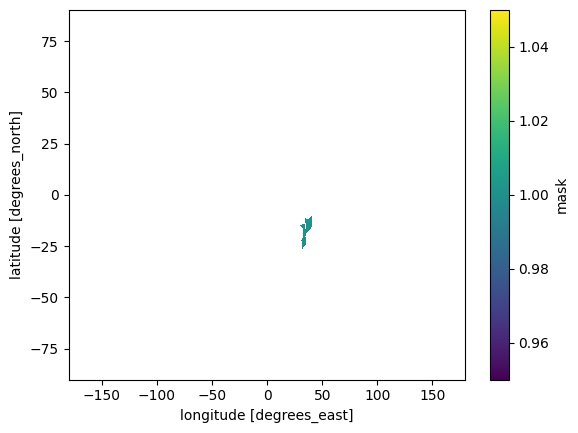

In [6]:
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].plot()
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].mask(lmask.lon, lmask.lat)
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

In [7]:
lon1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][0])
lon2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][2])
lat1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][1])
lat2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][3])
print(f"Bounding box: lats {lat1} to {lat2}, lons {lon1} to {lon2}")

Bounding box: lats -27 to -10, lons 30 to 41


## Drought indices

### Read drought index 

In [8]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
print(filelist[:20])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
print(drought_index[window])

['/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420101/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194201.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420201/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194202.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420301/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194203.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420401/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194204.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420501/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194205.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420601/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2020_194206.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19420701/hr/SPEI12_genlogistic_global_era5_moda_ref1991to2

### Mask drought index

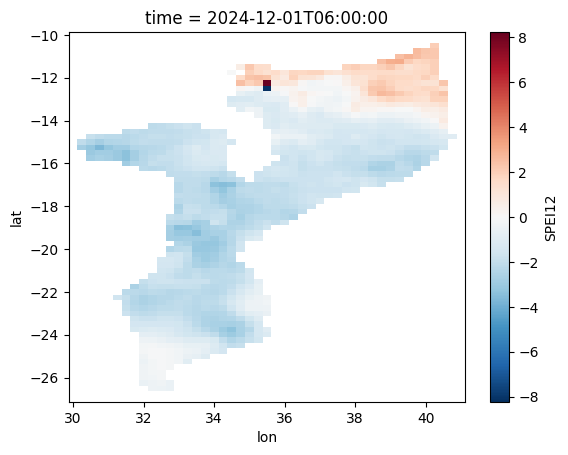

In [10]:
masked_drought_index = drought_index[window] * mask
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan
mask_cut = mask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
#area_2d.plot()
#area_2d_adj.plot()

### Calculate area in drought

In [11]:
#robinson = ccrs.Robinson().proj4_init

In [12]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (mask_cut*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries of area in drought

In [13]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']

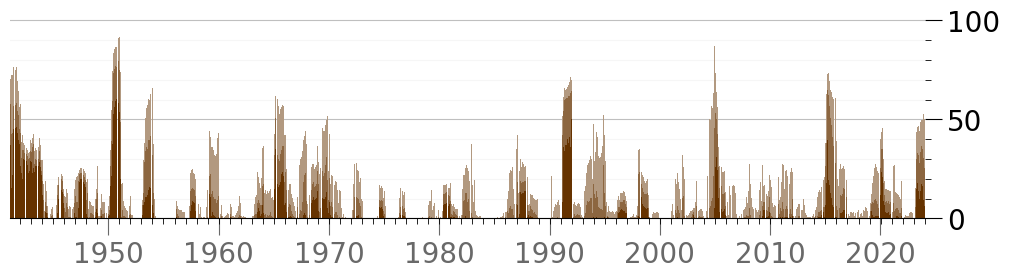

In [51]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
#title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
#fig.suptitle(f"{title1} | Percent of {country} in drought ({indicator}-{window})", fontsize=22)
#fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
#ax1.set_ylabel("Area in drought [%]", size=18)
#ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
#ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='dimgray')
ax1.xaxis.label.set_color('None')
ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
# Major ticks every 20, minor ticks every 5
#https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
#ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
# And a corresponding grid
#ax1.grid(which='minor')
# Or if you want different settings for the grids:
#ax.grid(which='minor', alpha=0.2)
#ax.grid(which='major', alpha=0.5)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
#for tick in ax1.get_xticklabels():
#    tick.set_rotation(45)
    
plt.savefig(f"figures/Mozambique_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

### Plot maps for specific events

time
1950-11-01 06:00:00    94.336814
1951-01-01 06:00:00    91.511300
1950-12-01 06:00:00    90.947572
1950-10-01 06:00:00    88.975022
2004-12-01 06:00:00    87.010912
1950-09-01 06:00:00    86.593270
1950-08-01 06:00:00    86.455335
1950-07-01 06:00:00    85.323998
1950-06-01 06:00:00    83.573100
1941-09-01 06:00:00    76.375533
dtype: float64
[117, 119, 118, 116, 766, 115, 114, 113, 112, 7]
1951-10


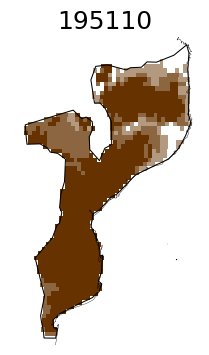

1951-12


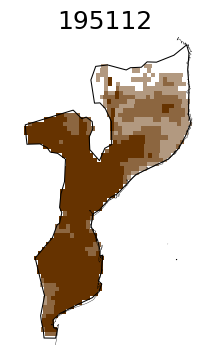

1951-11


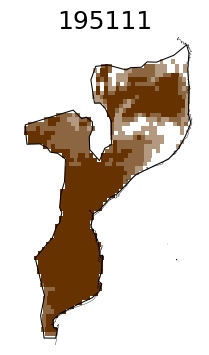

1951-09


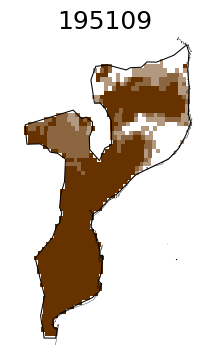

2005-11


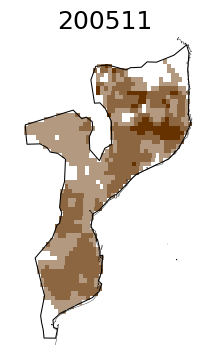

1951-08


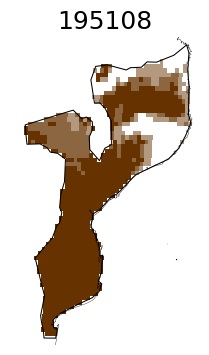

1951-07


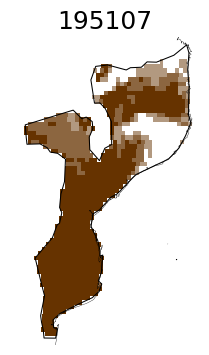

1951-06


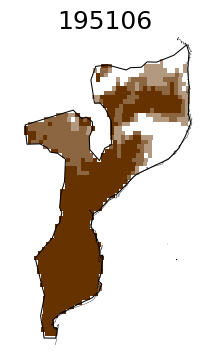

1951-05


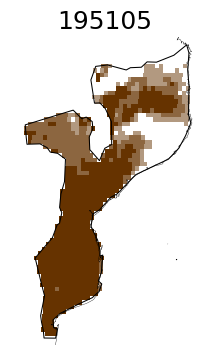

1942-08


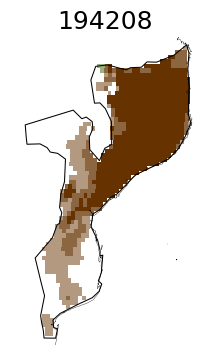

In [79]:
countries = shapereader.natural_earth(resolution='110m',
                              category='cultural',
                              name='admin_0_countries')

highlight_countries = [country]
for country in shapereader.Reader(countries).records():
    if country.attributes['ADMIN'] in highlight_countries:
        country_geom = country.geometry
        
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 16}
plt.rc('font', **font)

n = 10
nmax_indices = []
print(apidata.sum(axis=1).sort_values(ascending=False)[0:10,])
for i in range(n):
    nmax_indices.append(np.flatnonzero(apidata.index == apidata.sum(axis=1).sort_values(ascending=False).index[i])[0])
print(nmax_indices)
#i = 0
for itime in nmax_indices:
    toplot       = masked_drought_index.isel(time=itime)[f'{indicator}{window}']#['SPEI12'] * nutsmask_3d_xr.isel(time=itime)
    print(str(toplot.time.values)[:7])
    
    plt.figure(figsize=(4.5, 4));
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    ax.coastlines(color='black', lw=0.25)
    toplot.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=mycollisthex,
                              levels=mylevels)
    #ax.set_xlim([lon1,lon2])
    #ax.set_ylim([lat1,lat2])
    
    #title1 = r"$\bf{" + f"{string.ascii_lowercase[i]}" + "}$"
    #ax.set_title(f"{title1} | {str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    ax.set_title(f"{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    
    #ax.add_feature(cartopy.feature.BORDERS, color='black', lw=0.3)
    ax.add_geometries([country_geom], crs=ccrs.PlateCarree(), edgecolor='black', facecolor="None", linewidth=0.75)
    #plt.savefig(f"figures/{country}_{string.ascii_lowercase[i]}_map_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.pdf", dpi=300, format=None, metadata=None,
    plt.savefig(f"figures/Mozambique_map_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            #facecolor='auto', edgecolor='auto',
            transparent=True,
            backend=None)
    plt.show()
    #i += 1
    

In [73]:
# get n maximum drought events
# sort by max values: 
print(apidata.sum(axis=1).sort_values(ascending=False))


n = 10
nmax_indices = []
for i in range(n):
    nmax_indices.append(np.flatnonzero(apidata.index == apidata.sum(axis=1).sort_values(ascending=False).index[i])[0])
print(nmax_indices)

time
1950-11-01 06:00:00    94.336814
1951-01-01 06:00:00    91.511300
1950-12-01 06:00:00    90.947572
1950-10-01 06:00:00    88.975022
2004-12-01 06:00:00    87.010912
                         ...    
1955-05-01 06:00:00     0.000000
2012-03-01 06:00:00     0.000000
1989-01-01 06:00:00     0.000000
1989-02-01 06:00:00     0.000000
1984-03-01 06:00:00     0.000000
Length: 996, dtype: float64
[117, 119, 118, 116, 766, 115, 114, 113, 112, 7]
